In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from pathlib import Path
import json
from evaluate import Evaluator
import langextract.core.data as lxdata
import powerlaw

In [7]:
current = Path().cwd()
current_experiment = current / "experiments" / "FINAL" / "flash-min-base"
current_repo = current / "gh-docs-2026-02-19" / "content"

# distribution of the advices in documents:
with (current_experiment / "test.yaml").open("r") as f:
    test_documents = yaml.safe_load(f)

<Axes: ylabel='Frequency'>

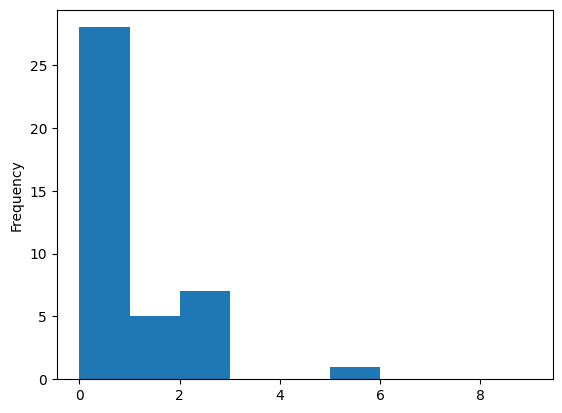

In [52]:
file_2_advices = [
    (file,len(extractions["extractions"])) for file,extractions in test_documents.items()
]

df = pd.DataFrame(file_2_advices,columns=["file","n"])
df["n"].plot.hist(bins=range(10))

Dataset Mean: 0.585
Dataset Variance: 1.099

Estimated Negative Binomial Parameters:
n (number of successes): 0.667
p (probability of success): 0.533


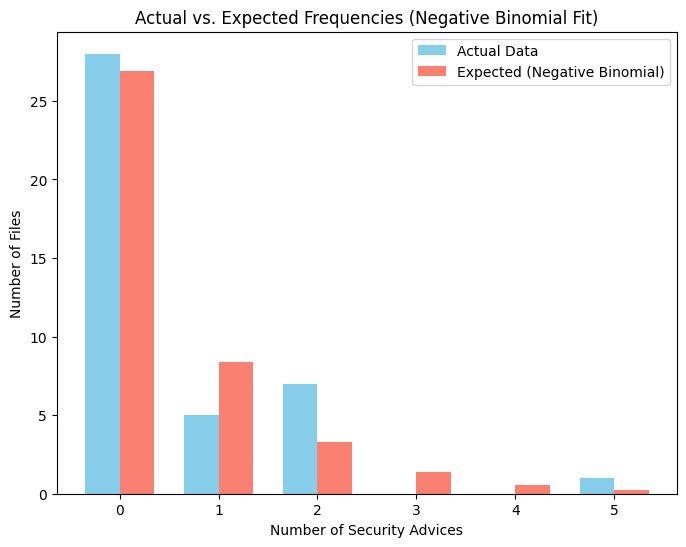

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import nbinom

# 1. Input your exact data
counts = np.array([0, 1, 2, 5])
frequencies = np.array([28, 5, 7, 1])

# Expand into a full array of 41 items to calculate stats easily
data = np.repeat(counts, frequencies)
total_files = len(data)

# 2. Calculate Mean and Variance
mean_val = np.mean(data)
var_val = np.var(data, ddof=1)

print(f"Dataset Mean: {mean_val:.3f}")
print(f"Dataset Variance: {var_val:.3f}")

# 3. Fit the Negative Binomial Distribution (Method of Moments)
# The formulas to convert mean and variance into nbinom parameters (n and p):
# p = mean / variance
# n = mean^2 / (variance - mean)
p = mean_val / var_val
n = (mean_val**2) / (var_val - mean_val)

print(f"\nEstimated Negative Binomial Parameters:")
print(f"n (number of successes): {n:.3f}")
print(f"p (probability of success): {p:.3f}")

# 4. Calculate Expected Frequencies based on the fit
# We check the range from 0 to 5 (your max count)
test_range = np.arange(0, 6)
expected_probs = nbinom.pmf(test_range, n, p)
expected_frequencies = expected_probs * total_files

# 5. Plot Actual vs Expected Frequencies
fig, ax = plt.subplots(figsize=(8, 6))

# Map actual frequencies to the 0-5 range for plotting
actual_full_range = np.zeros(6)
for c, f in zip(counts, frequencies):
    actual_full_range[c] = f

width = 0.35
ax.bar(test_range - width/2, actual_full_range, width, label='Actual Data', color='skyblue')
ax.bar(test_range + width/2, expected_frequencies, width, label='Expected (Negative Binomial)', color='salmon')

ax.set_xlabel('Number of Security Advices')
ax.set_ylabel('Number of Files')
ax.set_title('Actual vs. Expected Frequencies (Negative Binomial Fit)')
ax.set_xticks(test_range)
ax.legend()

plt.show()

In [37]:
file_2_biggest_advice = dict(
    (file,
        len(max(extractions["extractions"],key=lambda x: len(x["extraction_text"]),default={"extraction_text":""})["extraction_text"])
    ) for file,extractions in test_documents.items()
)
f"The biggest advice is {max(file_2_biggest_advice.values())} long. To add some headspace, we use {max(file_2_biggest_advice.values()) * 2} for now as the character buffer size. Recommended was 2000"

'The biggest advice is 961 long. To add some headspace, we use 1922 for now as the character buffer size. Recommended was 2000'

In [38]:
ev = Evaluator(current_experiment)
df = pd.DataFrame(columns=["file","IoU","Size_ref","Size_pre","Size_text","Size_ratio","Alignment"],data=ev.evaluate_per_extraction())
df

,file,IoU,Size_ref,Size_pre,Size_text,Size_ratio,Alignment
0,code-security/responsible-use/responsible-use-...,-0.470149,134,71,323,-0.47,match_lesser
1,code-security/responsible-use/responsible-use-...,-0.000000,307,307,458,0.00,match_lesser
2,code-security/concepts/secret-security/about-b...,-0.000000,169,169,169,0.00,match_exact
3,code-security/concepts/secret-security/about-b...,-0.553415,571,255,569,-0.55,match_lesser
4,code-security/how-tos/secure-your-supply-chain...,-0.000000,323,323,322,0.00,match_exact
5,actions/how-tos/secure-your-work/use-artifact-...,-0.000000,140,140,140,0.00,match_exact
6,actions/how-tos/secure-your-work/use-artifact-...,-0.000000,431,431,431,0.00,match_exact
7,code-security/how-tos/secure-your-supply-chain...,-0.000000,353,353,353,0.00,match_exact
8,code-security/how-tos/report-and-fix-vulnerabi...,-0.053512,299,283,841,-0.05,match_lesser
9,actions/how-tos/deploy/deploy-to-third-party-p...,-0.000000,283,283,283,0.00,match_exact


In [8]:
ev = Evaluator(current_experiment)

rows = []
for doc in ev.documents:
    for prediction in doc.extractions:
        if prediction.alignment_status == lxdata.AlignmentStatus.MATCH_EXACT:
            continue
        
        
        diff_prediction = prediction.char_interval.end_pos - prediction.char_interval.start_pos
        size = len(prediction.extraction_text)
        
        rows.append(
            (prediction.alignment_status.value,diff_prediction,size)
        )

df = pd.DataFrame(data=rows,columns=["Type","Interval","Actual"])
df["Diff"] = df["Interval"] - df["Actual"]
df.groupby("Type").aggregate(["mean","median"]).T

Type             match_fuzzy
Interval mean          364.6
         median        296.5
Actual   mean          361.4
         median        295.0
Diff     mean            3.2
         median          1.5

In [11]:
ev = Evaluator(current_experiment)
df = ev.evaluate_items()
df[df.Fuzzy != 0][["Prediction","Size","Fuzzy"]].corr("pearson")

,Prediction,Size,Fuzzy
Prediction,1.000000,0.525045,0.451770
Size,0.525045,1.000000,0.099788
Fuzzy,0.451770,0.099788,1.000000
